# Default of Credit Card Clients: EDA

Basic exploration of the columns and their distributions.

Input: `data/raw/` (the original file, never edited). Output: `data/curated/credit_default.csv` (cleaned, renamed and transformed), which the model notebook reads.

In [1]:
import io
import os
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scienceplots
import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)  # silence CMU font-weight warnings

RAW = '../data/raw/default_of_credit_card_clients.xls'
RAW_URL = 'https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.zip'
CURATED = '../data/curated/credit_default.csv'
PLOTS = '../plots'
os.makedirs(PLOTS, exist_ok=True)

plt.style.use(['science', 'no-latex', 'grid'])
plt.rcParams.update({
    'figure.dpi': 120, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'font.family': 'sans-serif', 'font.sans-serif': ['CMU Sans Serif'],
    'mathtext.fontset': 'custom', 'mathtext.rm': 'CMU Sans Serif',
    'mathtext.it': 'CMU Sans Serif:italic', 'mathtext.bf': 'CMU Sans Serif:bold',
    'axes.unicode_minus': False, 'axes.formatter.use_mathtext': False,  # CMU has no Unicode minus glyph
})

## Load data
The data folder is not in the repo. If the raw file is missing, download it from UCI and unzip it into `data/raw/`.

The first row of the sheet is an extra header (X1, X2, ...), so skip it.

## Feature names
The raw column names are renamed to short, readable ones:

| new name | raw name | meaning |
|---|---|---|
| `credit_limit` | LIMIT_BAL | credit limit (NT$) |
| `sex` | SEX | 1 = male, 2 = female |
| `education` | EDUCATION | 1 = grad school, 2 = university, 3 = high school, 4 = other |
| `marital_status` | MARRIAGE | 1 = married, 2 = single, 3 = other |
| `age` | AGE | age in years |
| `late_sep` … `late_apr` | PAY_0, PAY_2 … PAY_6 | repayment status that month (-2 = no bill, -1 = paid in full, 0 = paid the minimum, 1-9 = months late) |
| `bill_sep` … `bill_apr` | BILL_AMT1 … BILL_AMT6 | bill statement amount (NT$) |
| `paid_sep` … `paid_apr` | PAY_AMT1 … PAY_AMT6 | amount paid (NT$) |
| `default` | default payment next month | 1 = defaulted in Oct 2005 |

Months run Sep 2005 back to Apr 2005.

In [2]:
RENAME = {
    'ID': 'id', 'LIMIT_BAL': 'credit_limit', 'SEX': 'sex', 'EDUCATION': 'education',
    'MARRIAGE': 'marital_status', 'AGE': 'age', 'default payment next month': 'default',
    # repayment status (months late; -1 = paid on time), Sep 2005 back to Apr 2005
    'PAY_0': 'late_sep', 'PAY_2': 'late_aug', 'PAY_3': 'late_jul', 'PAY_4': 'late_jun', 'PAY_5': 'late_may', 'PAY_6': 'late_apr',
    # bill statement amount (NT$)
    'BILL_AMT1': 'bill_sep', 'BILL_AMT2': 'bill_aug', 'BILL_AMT3': 'bill_jul', 'BILL_AMT4': 'bill_jun', 'BILL_AMT5': 'bill_may', 'BILL_AMT6': 'bill_apr',
    # amount paid (NT$)
    'PAY_AMT1': 'paid_sep', 'PAY_AMT2': 'paid_aug', 'PAY_AMT3': 'paid_jul', 'PAY_AMT4': 'paid_jun', 'PAY_AMT5': 'paid_may', 'PAY_AMT6': 'paid_apr',
}
MONTHS = ['sep', 'aug', 'jul', 'jun', 'may', 'apr']

In [3]:
if not os.path.exists(RAW):
    os.makedirs(os.path.dirname(RAW), exist_ok=True)
    with urllib.request.urlopen(RAW_URL) as response:
        archive = zipfile.ZipFile(io.BytesIO(response.read()))
    with open(RAW, 'wb') as out:
        out.write(archive.read('default of credit card clients.xls'))
    print('downloaded', RAW)

df = pd.read_excel(RAW, header=1).rename(columns=RENAME)
df.shape

(30000, 25)

In [4]:
df.head()

,id,credit_limit,sex,education,marital_status,age,late_sep,late_aug,late_jul,late_jun,...,bill_jun,bill_may,bill_apr,paid_sep,paid_aug,paid_jul,paid_jun,paid_may,paid_apr,default
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


## Columns

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   id              30000 non-null  int64
 1   credit_limit    30000 non-null  int64
 2   sex             30000 non-null  int64
 3   education       30000 non-null  int64
 4   marital_status  30000 non-null  int64
 5   age             30000 non-null  int64
 6   late_sep        30000 non-null  int64
 7   late_aug        30000 non-null  int64
 8   late_jul        30000 non-null  int64
 9   late_jun        30000 non-null  int64
 10  late_may        30000 non-null  int64
 11  late_apr        30000 non-null  int64
 12  bill_sep        30000 non-null  int64
 13  bill_aug        30000 non-null  int64
 14  bill_jul        30000 non-null  int64
 15  bill_jun        30000 non-null  int64
 16  bill_may        30000 non-null  int64
 17  bill_apr        30000 non-null  int64
 18  paid_sep        30000 non-

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
credit_limit,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
sex,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
education,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
marital_status,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
age,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
late_sep,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
late_aug,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
late_jul,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
late_jun,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


In [7]:
df.isna().sum().sum()

np.int64(0)

In [8]:
df.nunique()

id                30000
credit_limit         81
sex                   2
education             7
marital_status        4
age                  56
late_sep             11
late_aug             11
late_jul             11
late_jun             11
late_may             10
late_apr             10
bill_sep          22723
bill_aug          22346
bill_jul          22026
bill_jun          21548
bill_may          21010
bill_apr          20604
paid_sep           7943
paid_aug           7899
paid_jul           7518
paid_jun           6937
paid_may           6897
paid_apr           6939
default               2
dtype: int64

## Categorical columns

In [9]:
categorical = ['sex', 'education', 'marital_status'] + [f'late_{m}' for m in MONTHS] + ['default']
for col in categorical:
    print(col)
    print(df[col].value_counts().sort_index(), '\n')

sex
sex
1    11888
2    18112
Name: count, dtype: int64 

education
education
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64 

marital_status
marital_status
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64 

late_sep
late_sep
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64 

late_aug
late_aug
-2     3782
-1     6050
 0    15730
 1       28
 2     3927
 3      326
 4       99
 5       25
 6       12
 7       20
 8        1
Name: count, dtype: int64 

late_jul
late_jul
-2     4085
-1     5938
 0    15764
 1        4
 2     3819
 3      240
 4       76
 5       21
 6       23
 7       27
 8        3
Name: count, dtype: int64 

late_jun
late_jun
-2     4348
-1     5687
 0    16455
 1        2
 2     3159
 3      180
 4       69
 5       35
 6        5
 7       58
 8        2
Name: count, dtype: int64 

lat

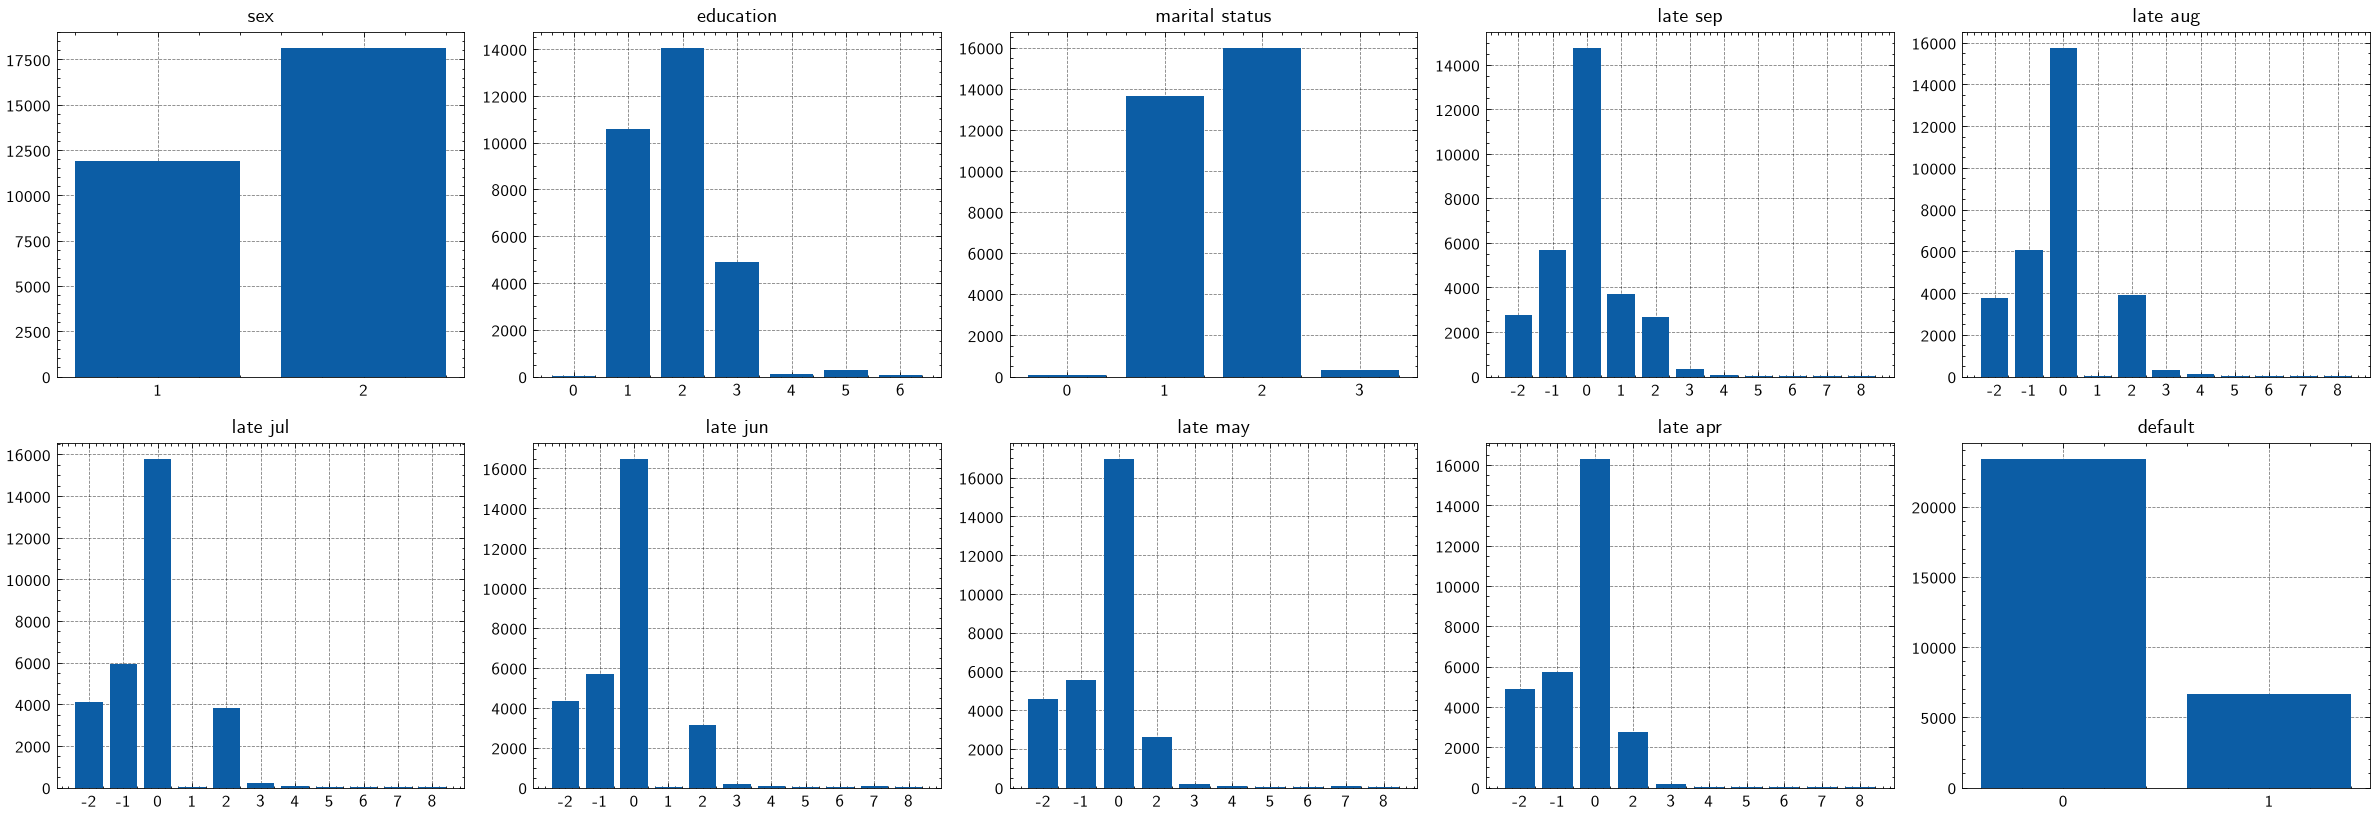

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.flat, categorical):
    counts = df[col].value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values)
    ax.set_title(col.replace('_', ' '))
plt.tight_layout()
plt.savefig(f'{PLOTS}/categorical_counts.png')
plt.show()

## Numeric columns

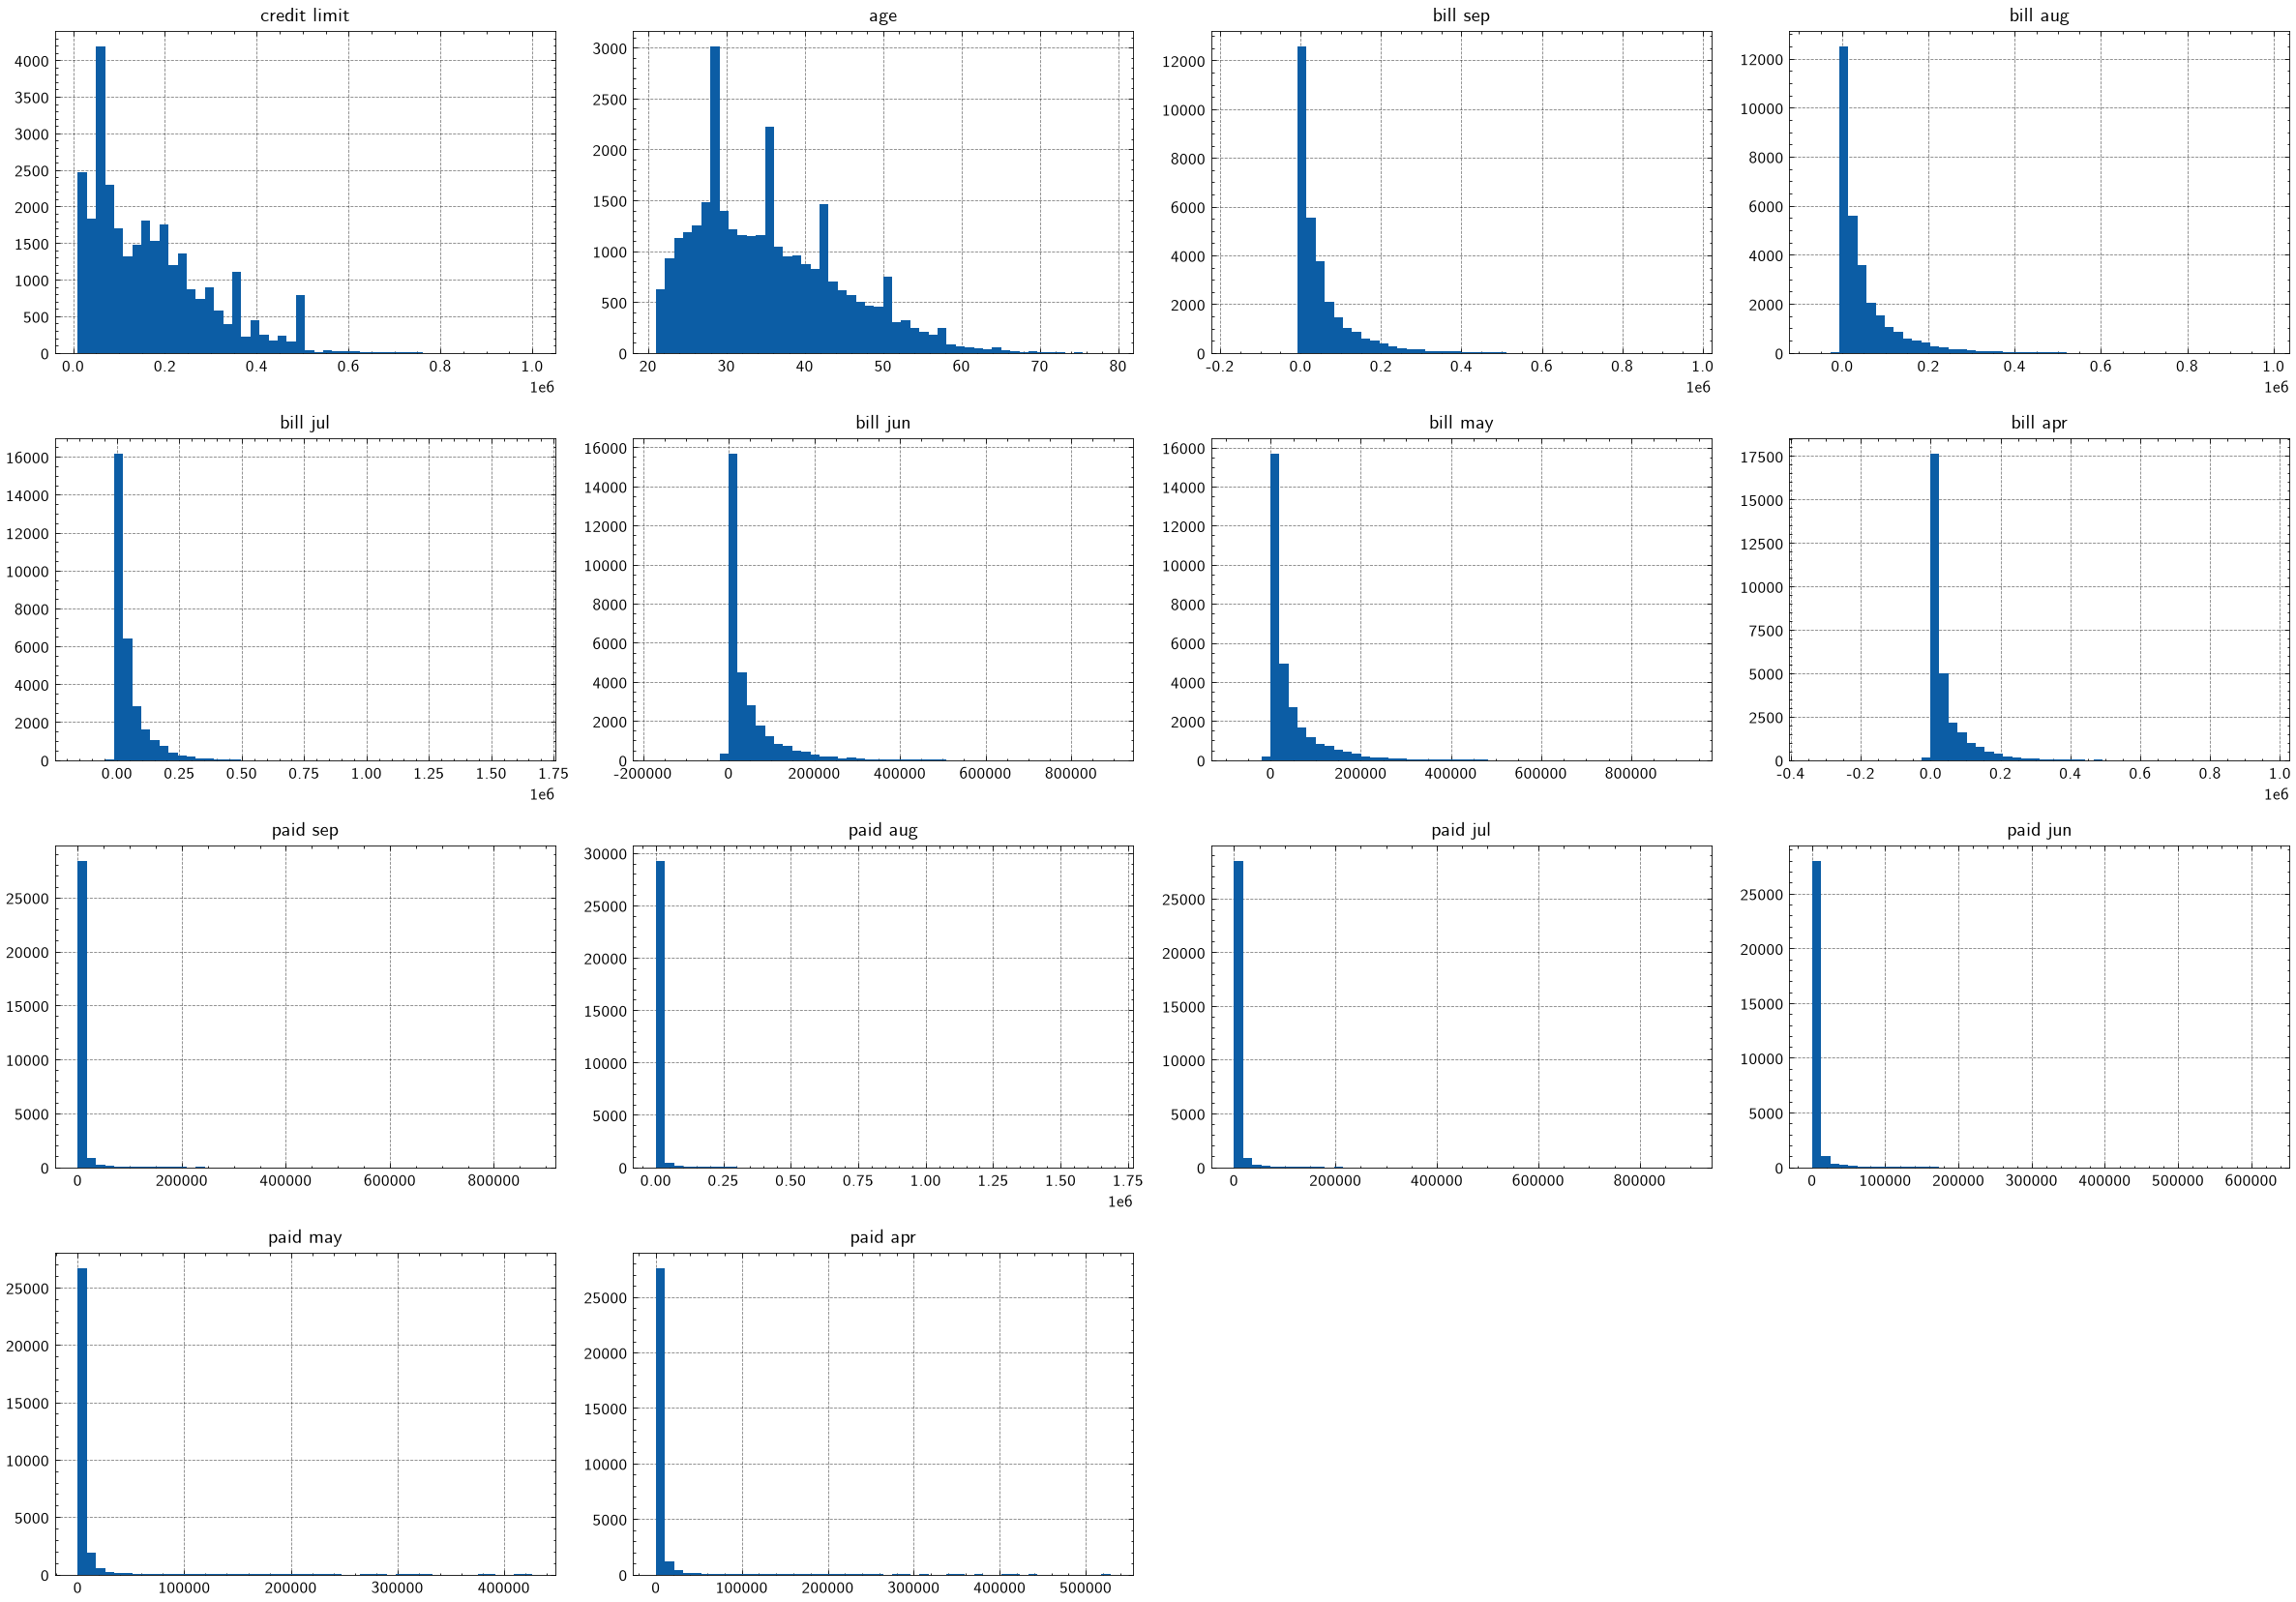

In [11]:
numeric = ['credit_limit', 'age'] + [f'bill_{m}' for m in MONTHS] + [f'paid_{m}' for m in MONTHS]

fig, axes = plt.subplots(4, 4, figsize=(20, 14))
for ax, col in zip(axes.flat, numeric):
    ax.hist(df[col], bins=50)
    ax.set_title(col.replace('_', ' '))
for ax in axes.flat[len(numeric):]:
    ax.axis('off')
plt.tight_layout()
plt.savefig(f'{PLOTS}/numeric_histograms.png')
plt.show()

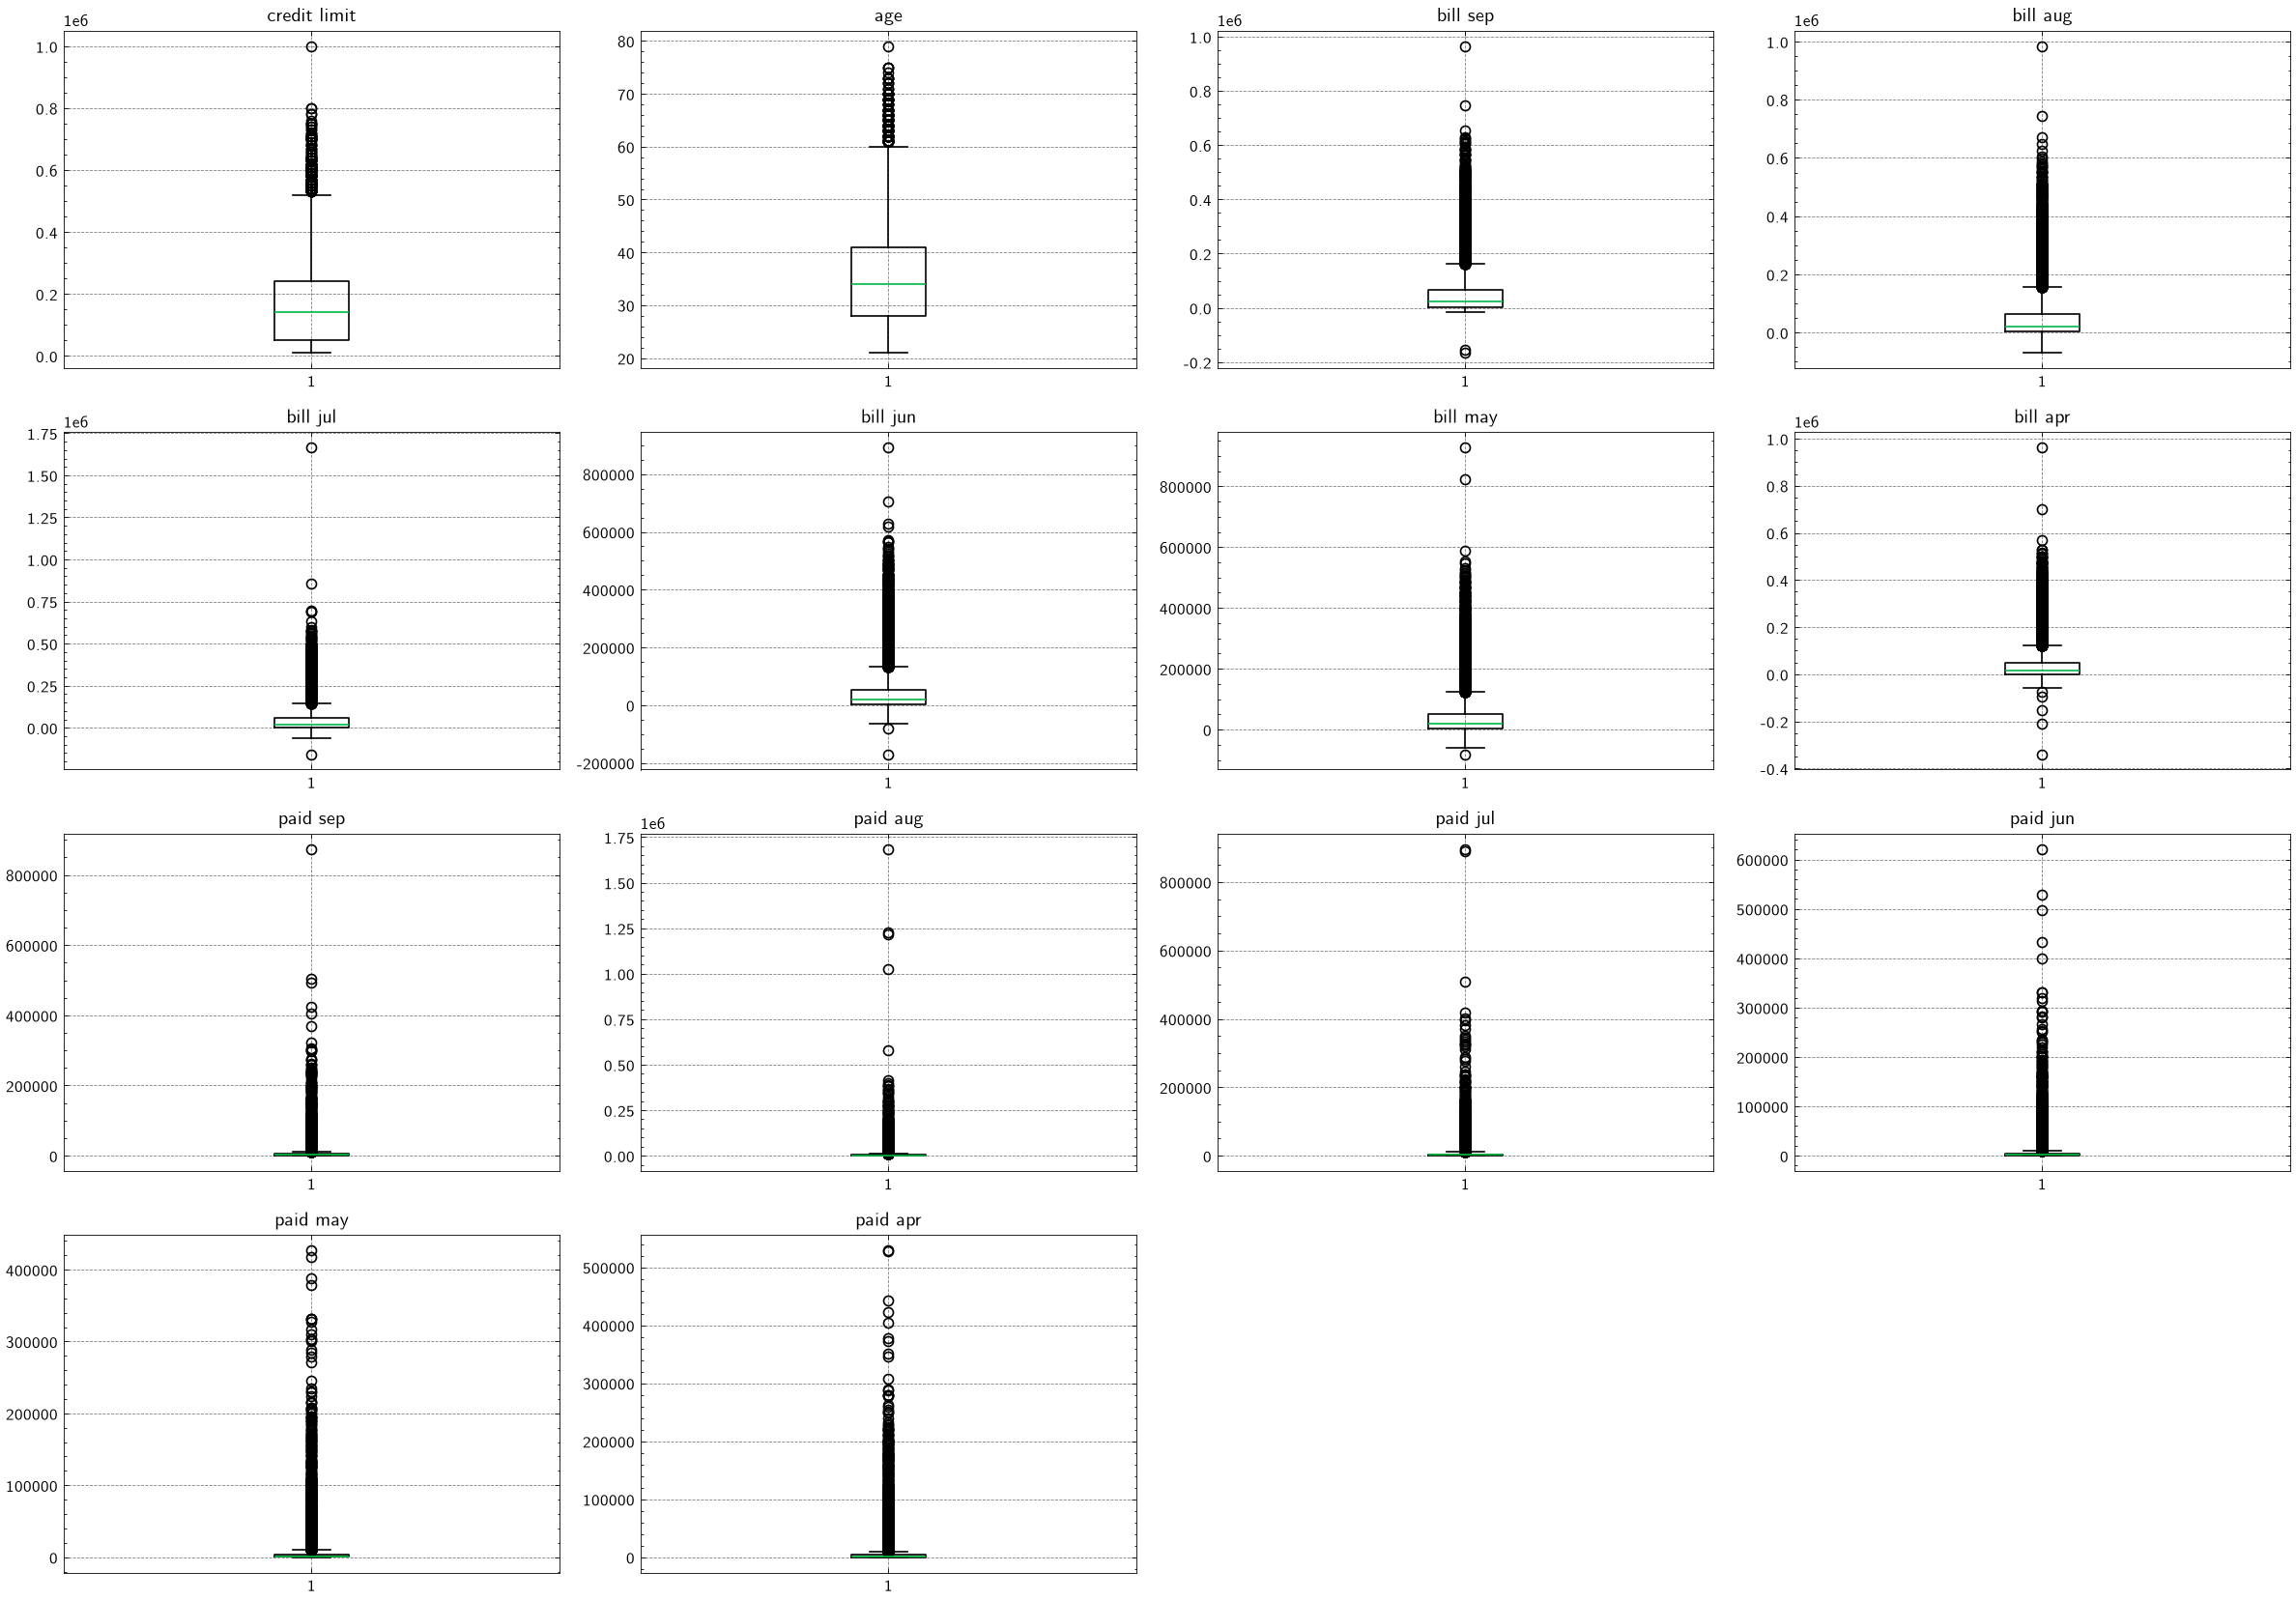

In [12]:
fig, axes = plt.subplots(4, 4, figsize=(20, 14))
for ax, col in zip(axes.flat, numeric):
    ax.boxplot(df[col])
    ax.set_title(col.replace('_', ' '))
for ax in axes.flat[len(numeric):]:
    ax.axis('off')
plt.tight_layout()
plt.savefig(f'{PLOTS}/numeric_boxplots.png')
plt.show()

## Target vs a few features

default
0    0.7788
1    0.2212
Name: proportion, dtype: float64


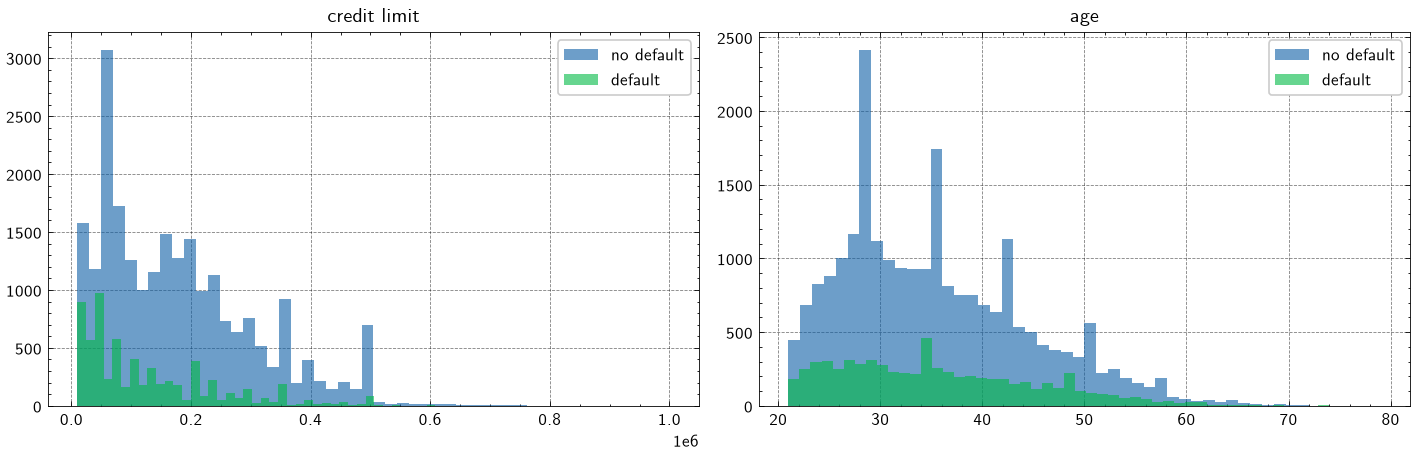

In [13]:
print(df['default'].value_counts(normalize=True))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['credit_limit', 'age']):
    ax.hist(df.loc[df['default'] == 0, col], bins=50, alpha=0.6, label='no default')
    ax.hist(df.loc[df['default'] == 1, col], bins=50, alpha=0.6, label='default')
    ax.set_title(col.replace('_', ' '))
    ax.legend()
plt.tight_layout()
plt.savefig(f'{PLOTS}/credit_limit_age_by_default.png')
plt.show()

## Correlations

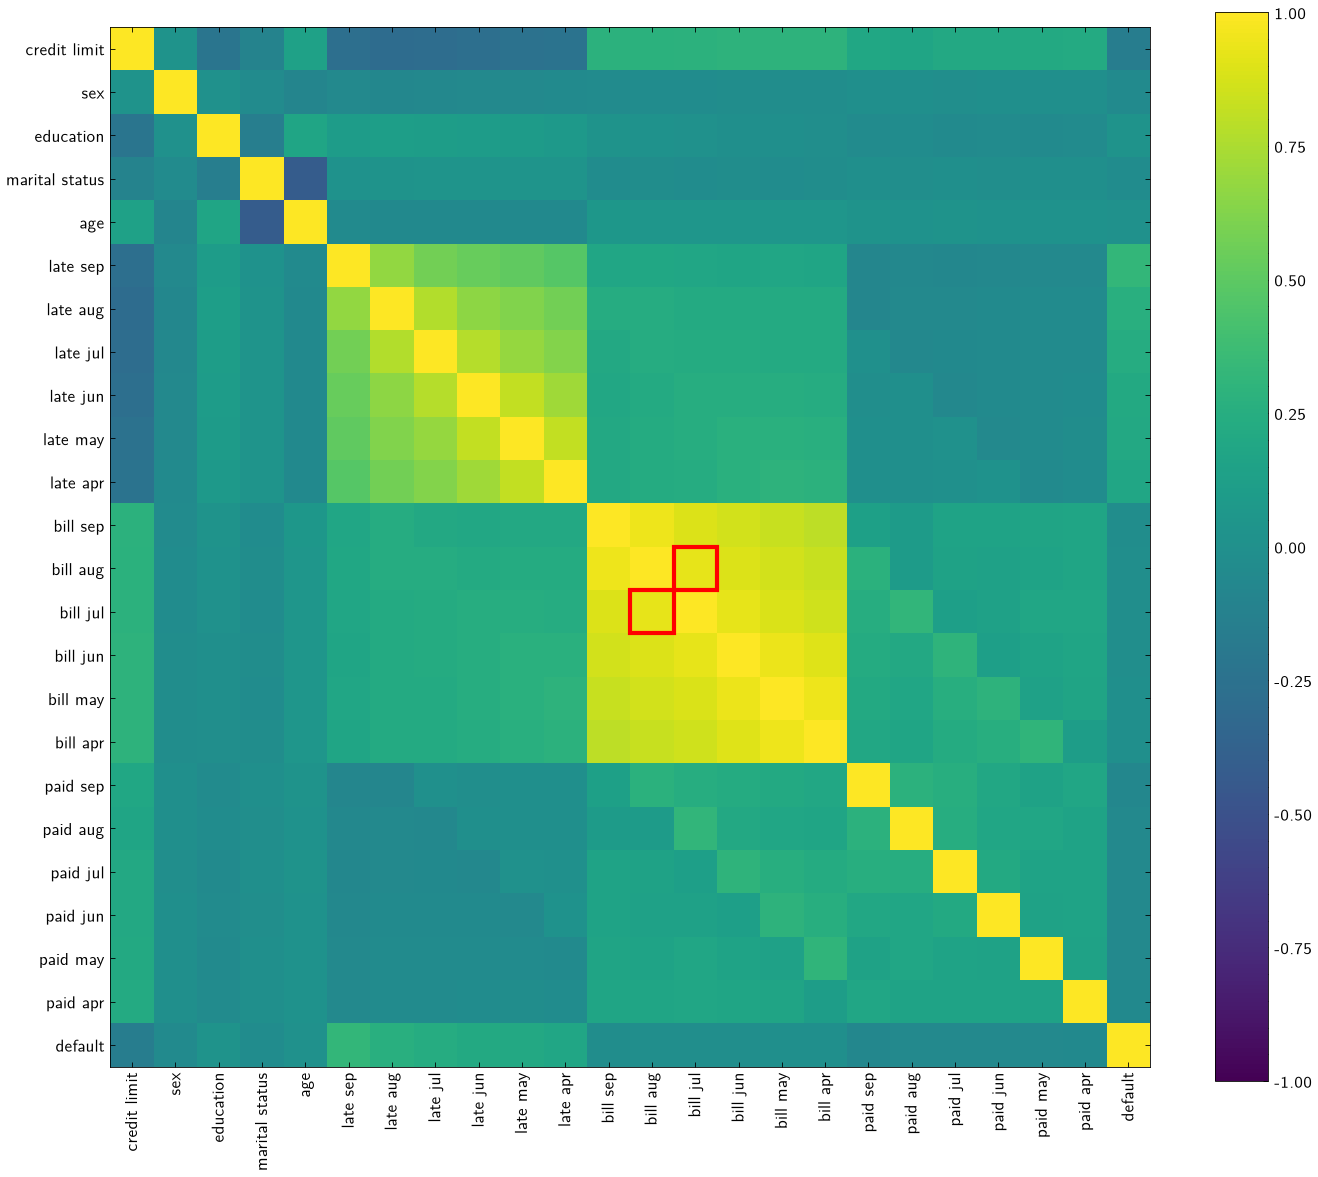

corr(bill_jul, bill_aug) = 0.928


In [14]:
corr = df.drop(columns='id').corr()
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns.str.replace('_', ' '), rotation=90)
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns.str.replace('_', ' '))
ax.grid(False)
ax.minorticks_off()

# highlight one strongly correlated pair (both symmetric cells)
i, j = corr.columns.get_loc('bill_jul'), corr.columns.get_loc('bill_aug')
for r, c in [(i, j), (j, i)]:
    ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, edgecolor='red', linewidth=2.5))
fig.colorbar(im)
plt.tight_layout()
plt.savefig(f'{PLOTS}/correlation_matrix.png')
plt.show()
print(f"corr(bill_jul, bill_aug) = {corr.loc['bill_jul', 'bill_aug']:.3f}")

Bill amounts in consecutive months are almost the same number (one pair is boxed in red above), because an unpaid balance carries over to the next statement. The scatter shows `bill_jul` against `bill_aug`: most clients lie on the diagonal.

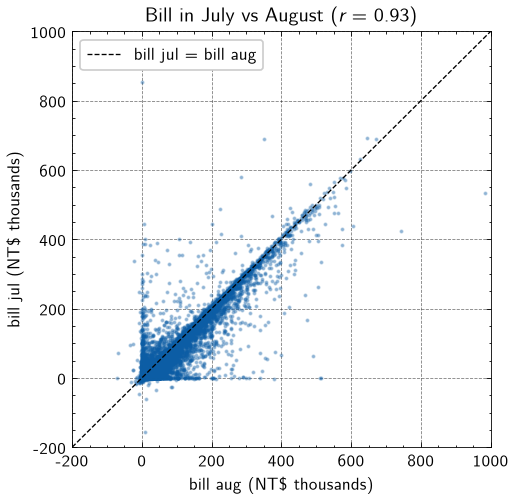

In [15]:
r = corr.loc['bill_jul', 'bill_aug']
plt.figure(figsize=(4.5, 4.5))
plt.scatter(df['bill_aug'] / 1000, df['bill_jul'] / 1000, s=2, alpha=0.3)
lim = [-200, 1000]
plt.plot(lim, lim, 'k--', linewidth=0.8, label='bill jul = bill aug')
plt.xlim(lim)
plt.ylim(lim)
plt.xlabel('bill aug (NT\\$ thousands)')
plt.ylabel('bill jul (NT\\$ thousands)')
plt.title(f'Bill in July vs August ($r$ = {r:.2f})')
plt.legend(loc='upper left')
plt.savefig(f'{PLOTS}/bill_jul_vs_aug.png')
plt.show()

# Transformations
## Cleaning
`education` codes 0, 5 and 6 are not documented, so they are folded into 4 = other. `marital_status` 0 is folded into 3 = other.

In [16]:
df['education'] = df['education'].replace({0: 4, 5: 4, 6: 4})
df['marital_status'] = df['marital_status'].replace({0: 3})
df['education'].value_counts().sort_index(), df['marital_status'].value_counts().sort_index()

(education
 1    10585
 2    14030
 3     4917
 4      468
 Name: count, dtype: int64,
 marital_status
 1    13659
 2    15964
 3      377
 Name: count, dtype: int64)

## Negative bills
`paid_*` and `credit_limit` are never negative, but `bill_*` sometimes is. (The negative `late_*` values are codes, not money: -2 = no bill, -1 = paid in full.)

In [17]:
bill_cols = [f'bill_{m}' for m in MONTHS]
neg = df[bill_cols] < 0
print('negative bills per month:')
print(neg.sum().to_string())
print(f'clients with any negative bill: {neg.any(axis=1).sum()} ({neg.any(axis=1).mean():.1%})')

neg_values = df[bill_cols][neg].stack()
print(f'median negative bill: {neg_values.median():.0f}, smallest: {neg_values.min():.0f}')
print(f'default rate: with a negative bill {df.loc[neg.any(axis=1), "default"].mean():.3f}, '
      f'without {df.loc[~neg.any(axis=1), "default"].mean():.3f}')

negative bills per month:
bill_sep    590
bill_aug    669
bill_jul    655
bill_jun    675
bill_may    655
bill_apr    688
clients with any negative bill: 1930 (6.4%)
median negative bill: -158, smallest: -339603
default rate: with a negative bill 0.165, without 0.225


A negative bill is a **credit balance**: the client paid more than they owed (or got a refund), so the bank owes them. Most are tiny (median about -158 NT$), and these clients default *less* often, so they are real and informative. But a few are suspicious:

In [18]:
too_big = (df[bill_cols].min(axis=1) < -df['credit_limit'])
print(too_big.sum(), 'clients have a credit balance larger than their whole credit limit')
df.loc[too_big, ['credit_limit'] + bill_cols + [f'paid_{m}' for m in MONTHS]]

6 clients have a credit balance larger than their whole credit limit


,credit_limit,bill_sep,bill_aug,bill_jul,bill_jun,bill_may,bill_apr,paid_sep,paid_aug,paid_jul,paid_jun,paid_may,paid_apr
290,280000,898,898,325,898,325,-339603,898,325,898,325,0,345293
7688,10000,219,9110,9797,-10433,9767,9067,10400,1000,0,20200,200,0
12828,100000,100000,0,0,0,0,-150953,0,0,0,0,0,150400
18876,60000,44912,11409,-61506,3859,415,415,144047,365,73000,415,415,50136
21729,50000,0,-69777,0,0,0,0,0,70000,0,0,0,0
27327,20000,19131,17834,18790,-27490,20001,17985,1500,1400,0,47700,700,1000


In [19]:
odd = (df['bill_sep'] < 0) & (df['late_sep'] >= 1)
print(odd.sum(), 'clients are coded as late in September while the bank owes them money')

377 clients are coded as late in September while the bank owes them money


Cleaning:
1. **Drop** the clients whose credit balance is larger than their credit limit. They line up with huge one-off payments (refunds/reversals), not normal card use.
2. **Clip** negative bills to 0: the client owes nothing that month.
3. **Keep the information** in a new feature, `credit_balance_months`: the number of months (out of six) with a credit balance.

The "late while in credit" codes contradict each other, but there is no reliable way to fix them, so they are left as they are.

In [20]:
df = df[~too_big].copy()
df['credit_balance_months'] = (df[bill_cols] < 0).sum(axis=1)
df[bill_cols] = df[bill_cols].clip(lower=0)
print(df.shape, ' min bill now:', df[bill_cols].min().min())

(29994, 26)  min bill now: 0


## Log transform of money columns
The bill and payment amounts are strongly right-skewed: most clients have small amounts and a few have very large ones. Taking logs spreads out the small values and pulls in the extreme ones.

All money columns are now 0 or more, so we use `log(1 + x)` (the `+1` handles zeros).

In [21]:
df['log_credit_limit'] = np.log1p(df['credit_limit'])
for m in MONTHS:
    df[f'log_bill_{m}'] = np.log1p(df[f'bill_{m}'])
    df[f'log_paid_{m}'] = np.log1p(df[f'paid_{m}'])

print('skewness before -> after')
for col in ['credit_limit', 'bill_sep', 'paid_sep']:
    print(f'{col:14s} {df[col].skew():6.2f} -> {df["log_" + col].skew():6.2f}')

skewness before -> after
credit_limit     0.99 ->  -0.51
bill_sep         2.67 ->  -1.72
paid_sep        14.70 ->  -1.29


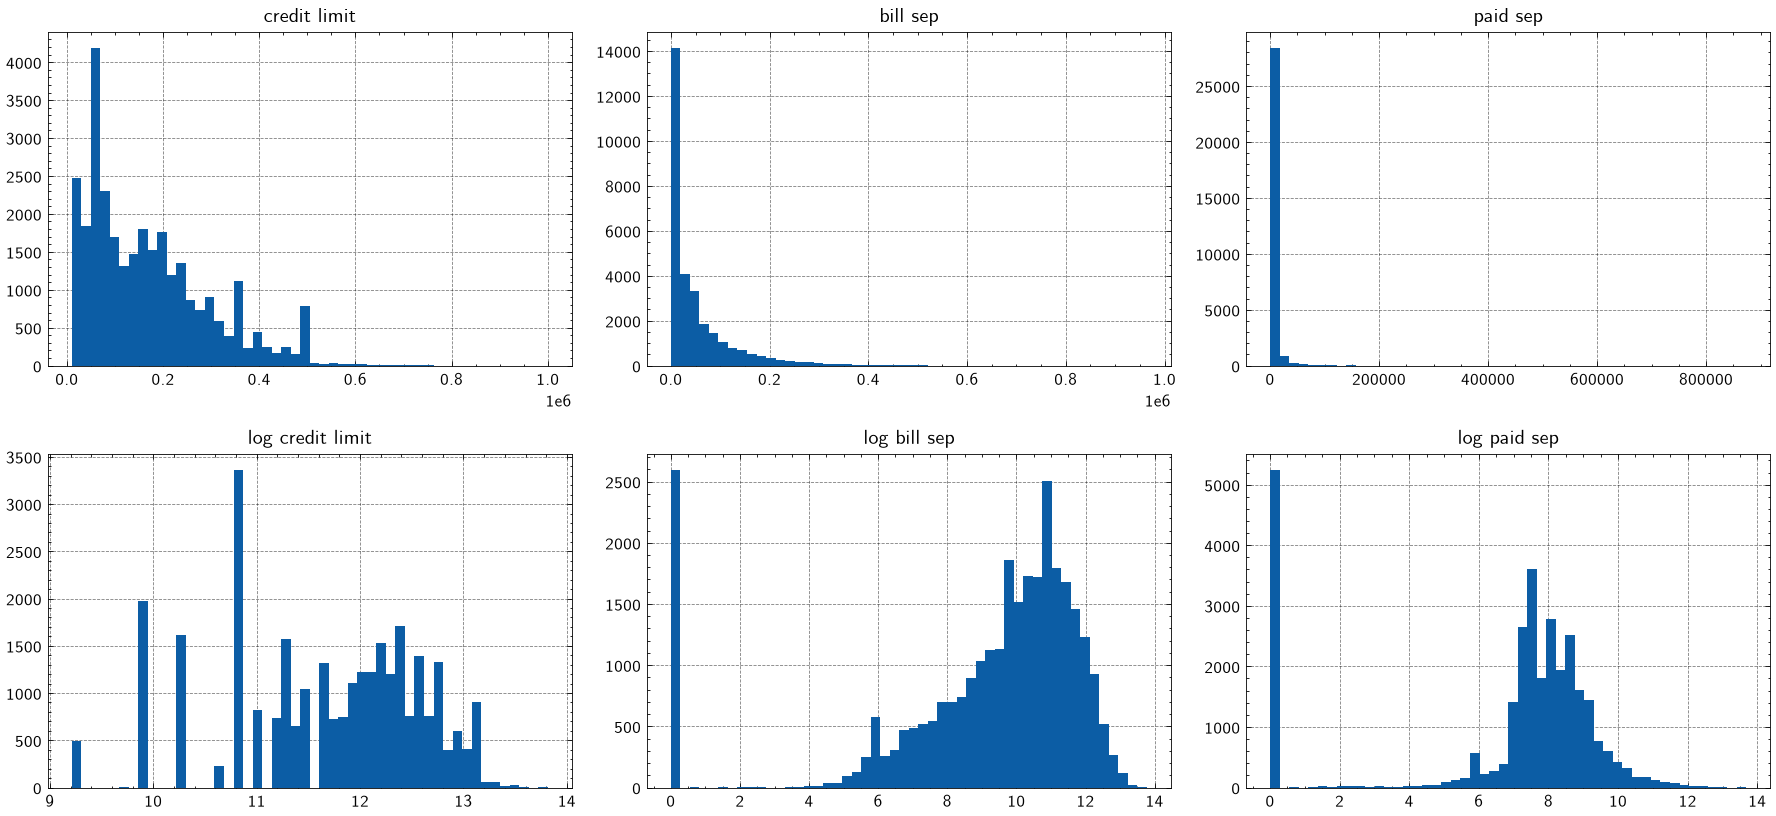

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for i, col in enumerate(['credit_limit', 'bill_sep', 'paid_sep']):
    axes[0, i].hist(df[col], bins=50)
    axes[0, i].set_title(col.replace('_', ' '))
    axes[1, i].hist(df['log_' + col], bins=50)
    axes[1, i].set_title('log ' + col.replace('_', ' '))
plt.tight_layout()
plt.savefig(f'{PLOTS}/log_transform.png')
plt.show()

## New features
- `female`, `edu_university`, `edu_high_school`, `edu_other`, `single`, `marital_other`: 0/1 columns for the categories (baseline: male, grad school, married).
- `late_sep_m2`, `late_sep_m1`, `late_sep_1`, `late_sep_2`, `late_sep_3plus`: `late_sep` as 0/1 columns. Its codes are not evenly spaced (-2 = no bill, -1 = paid in full, 0 = paid the minimum, 1+ = months late), so one slope can't describe them well. Baseline: 0.
- `util_*`: bill divided by credit limit (share of the limit used).
- `months_late`: number of months out of six the client was late.
- `credit_balance_months`: number of months with a credit balance (made in the cleaning step above).

In [23]:
df['female'] = (df['sex'] == 2).astype(int)
df['edu_university'] = (df['education'] == 2).astype(int)
df['edu_high_school'] = (df['education'] == 3).astype(int)
df['edu_other'] = (df['education'] == 4).astype(int)
df['single'] = (df['marital_status'] == 2).astype(int)
df['marital_other'] = (df['marital_status'] == 3).astype(int)

df['late_sep_m2'] = (df['late_sep'] == -2).astype(int)
df['late_sep_m1'] = (df['late_sep'] == -1).astype(int)
df['late_sep_1'] = (df['late_sep'] == 1).astype(int)
df['late_sep_2'] = (df['late_sep'] == 2).astype(int)
df['late_sep_3plus'] = (df['late_sep'] >= 3).astype(int)

for m in MONTHS:
    df[f'util_{m}'] = df[f'bill_{m}'] / df['credit_limit']
df['months_late'] = (df[[f'late_{m}' for m in MONTHS]] > 0).sum(axis=1)

## Interaction terms
An interaction is the product of two features. It lets the effect of one feature depend on the other, e.g. being late may matter more for a client who is already using most of their limit.

- `late_x_util`: `late_sep` × `util_sep`
- `late_x_limit`: `late_sep` × `log_credit_limit`
- `months_late_x_util`: `months_late` × `util_sep`
- `age_x_limit`: `age` × `log_credit_limit`
- `late_sep_x_aug`: `late_sep` × `late_aug` (late two months in a row)

In [24]:
df['late_x_util'] = df['late_sep'] * df['util_sep']
df['late_x_limit'] = df['late_sep'] * df['log_credit_limit']
df['months_late_x_util'] = df['months_late'] * df['util_sep']
df['age_x_limit'] = df['age'] * df['log_credit_limit']
df['late_sep_x_aug'] = df['late_sep'] * df['late_aug']

new = ['late_x_util', 'late_x_limit', 'months_late_x_util', 'age_x_limit', 'late_sep_x_aug']
df[new + ['default']].corr()['default'].round(3)

late_x_util           0.301
late_x_limit          0.317
months_late_x_util    0.325
age_x_limit          -0.037
late_sep_x_aug        0.158
default               1.000
Name: default, dtype: float64

## Save the curated data
Scaling (subtracting the mean, dividing by the SD) is **not** done here. It must use statistics from the training set only, so it happens in the model notebook after the train/test split.

In [25]:
os.makedirs(os.path.dirname(CURATED), exist_ok=True)
df.to_csv(CURATED, index=False)
print(df.shape, '->', CURATED)

(29994, 62) -> ../data/curated/credit_default.csv
